
 MEGNet Training & Evaluation (on Heusler Dataset)


In [ ]:
# ── Imports ──────────────────────────────────────────────────
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from megnet.models import MEGNetModel
from megnet.data.crystal import CrystalGraph

In [ ]:
# ── Config ───────────────────────────────────────────────────
GRAPHS_PATH   = "heusler_graphs.pkl"
MODEL_DIR     = "callback"
CUTOFF        = 10          # Å  (MEGNet default is 5)
NFEAT_BOND    = 100
GAUSS_WIDTH   = 0.5
LR            = 1e-3
EPOCHS        = 100
BATCH_SIZE    = 64
PATIENCE      = 50          # MEGNet was 500 (exceeded EPOCHS)
RANDOM_STATE  = 42
TEST_SIZE     = 0.15        # 15 % → temp;  temp split 50/50 → val / test

In [ ]:
# ── 1. Load Graphs ───────────────────────────────────────────
with open(GRAPHS_PATH, "rb") as f:
    data = pickle.load(f)

graphs  = data["graphs"]
targets = data["targets"]

print(f"Graphs : {len(graphs)}")
print(f"Targets: {len(targets)}")
assert len(graphs) == len(targets), "Graph / target count mismatch!"

Graphs : 8166
Targets: 8166


In [ ]:
# ── 2. Data Split ────────────────────────────────────────────
train_graphs, temp_graphs, train_targets, temp_targets = train_test_split(
    graphs, targets, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
val_graphs, test_graphs, val_targets, test_targets = train_test_split(
    temp_graphs, temp_targets, test_size=0.5, random_state=RANDOM_STATE
)

print(f"Train : {len(train_graphs)}")
print(f"Val   : {len(val_graphs)}")
print(f"Test  : {len(test_graphs)}")

Train : 6941
Val   : 612
Test  : 613


In [ ]:
# ── 3. Build Model ───────────────────────────────────────────
centers = np.linspace(0, CUTOFF, NFEAT_BOND)
graph_converter = CrystalGraph(cutoff=CUTOFF)
model = MEGNetModel(
    graph_converter=graph_converter,
    centers=centers,
    width=GAUSS_WIDTH,
    lr=LR,
    loss="mse",
    metrics=["mae"],
)
print("Model initialised.")

C:\Users\taluk\anaconda3\envs\megnet_env\lib\site-packages\keras\initializers\initializers_v2.py:120: UserWarning: The initializer GlorotUniform is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(


Model initialised.


C:\Users\taluk\anaconda3\envs\megnet_env\lib\site-packages\keras\optimizers\optimizer_v2\adam.py:114: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


In [ ]:
#Remove old checkpoints
#____________________________________________________

import shutil
import os

if os.path.exists("callback"):
    shutil.rmtree("callback")

os.makedirs("callback", exist_ok=True)

print("Fresh callback folder created")

Fresh callback folder created


In [ ]:
#Remove old outputs
#____________________________________________________

files_to_remove = [
    "megnet_trained.h5",
    "megnet_results.json",
    "megnet_results.png"
]

for f in files_to_remove:
    if os.path.exists(f):
        os.remove(f)

print("Old outputs removed")

Old outputs removed


In [ ]:
# ── 4. Train ─────────────────────────────────────────────────
history = model.train_from_graphs(
    train_graphs,
    train_targets,
    validation_graphs=val_graphs,
    validation_targets=val_targets,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    patience=PATIENCE,
)

Epoch 1/100
1/1 [==============================] - 6s 6s/step


INFO:megnet.callbacks:
Epoch 00001: val_mae improved from inf to 0.28728, saving model to callback\val_mae_00001_0.287278.hdf5


109/109 [==============================] - 180s 1s/step - loss: 0.5306 - mae: 0.4715
Epoch 2/100
1/1 [==============================] - 0s 295ms/step


INFO:megnet.callbacks:
Epoch 00002: val_mae improved from 0.28728 to 0.22437, saving model to callback\val_mae_00002_0.224369.hdf5


109/109 [==============================] - 158s 1s/step - loss: 0.1332 - mae: 0.2566
Epoch 3/100
109/109 [==============================] - 131s 1s/step - loss: 0.0995 - mae: 0.2259
Epoch 4/100
1/1 [==============================] - 0s 350ms/step


...

109/109 [==============================] - 199s 2s/step - loss: 0.0213 - mae: 0.0960
Epoch 83/100
109/109 [==============================] - 199s 2s/step - loss: 0.0223 - mae: 0.0980
Epoch 84/100
109/109 [==============================] - 198s 2s/step - loss: 0.0211 - mae: 0.0954
Epoch 85/100
109/109 [==============================] - 200s 2s/step - loss: 0.0215 - mae: 0.0960
Epoch 86/100
109/109 [==============================] - 202s 2s/step - loss: 0.0209 - mae: 0.0945
Epoch 87/100
109/109 [==============================] - 206s 2s/step - loss: 0.0217 - mae: 0.0971
Epoch 88/100
109/109 [==============================] - 206s 2s/step - loss: 0.0213 - mae: 0.0967
Epoch 89/100
1/1 [==============================] - 0s 331ms/step


INFO:megnet.callbacks:
Epoch 00089: val_mae improved from 0.09567 to 0.09219, saving model to callback\val_mae_00089_0.092188.hdf5


109/109 [==============================] - 210s 2s/step - loss: 0.0212 - mae: 0.0938
Epoch 90/100
109/109 [==============================] - 210s 2s/step - loss: 0.0248 - mae: 0.1007
Epoch 91/100
109/109 [==============================] - 209s 2s/step - loss: 0.0217 - mae: 0.0915
Epoch 92/100
1/1 [==============================] - 0s 347ms/step


INFO:megnet.callbacks:
Epoch 00092: val_mae improved from 0.09219 to 0.08913, saving model to callback\val_mae_00092_0.089126.hdf5


109/109 [==============================] - 212s 2s/step - loss: 0.0184 - mae: 0.0863
Epoch 93/100
109/109 [==============================] - 214s 2s/step - loss: 0.0186 - mae: 0.0863
Epoch 94/100
109/109 [==============================] - 216s 2s/step - loss: 0.0177 - mae: 0.0841
Epoch 95/100
109/109 [==============================] - 219s 2s/step - loss: 0.0174 - mae: 0.0828
Epoch 96/100
109/109 [==============================] - 219s 2s/step - loss: 0.0168 - mae: 0.0814
Epoch 97/100
109/109 [==============================] - 214s 2s/step - loss: 0.0174 - mae: 0.0845
Epoch 98/100
109/109 [==============================] - 215s 2s/step - loss: 0.0181 - mae: 0.0864
Epoch 99/100
109/109 [==============================] - 214s 2s/step - loss: 0.0172 - mae: 0.0839
Epoch 100/100
109/109 [==============================] - 215s 2s/step - loss: 0.0181 - mae: 0.0877


In [ ]:
# ── 5. Load Best Checkpoint ──────────────────────────────────
if not os.path.isdir(MODEL_DIR):
    raise FileNotFoundError(
        f"Checkpoint directory '{MODEL_DIR}' not found. "
        "Make sure MEGNet's callback saved weights there."
    )
hdf5_files = [f for f in os.listdir(MODEL_DIR) if f.endswith(".hdf5")]
if not hdf5_files:
    raise FileNotFoundError(f"No .hdf5 checkpoints found in '{MODEL_DIR}'.")

print("Checkpoints found:")
for f in hdf5_files:
    print(f"  {f}")


def parse_val_loss(fname):
    try:
        return float(fname.split("_")[-1].replace(".hdf5", ""))
    except ValueError:
        return float("inf")

hdf5_files.sort(key=parse_val_loss)
best_model_path = os.path.join(MODEL_DIR, hdf5_files[0])
print(f"\nBest checkpoint: {best_model_path}")

model.load_weights(best_model_path)
print("Best model weights loaded successfully.")

Checkpoints found:
  val_mae_00001_0.287278.hdf5
  val_mae_00002_0.224369.hdf5
  val_mae_00004_0.203054.hdf5
  val_mae_00005_0.197297.hdf5
  val_mae_00006_0.174625.hdf5
  val_mae_00007_0.160539.hdf5
  val_mae_00008_0.145760.hdf5
  val_mae_00010_0.140610.hdf5
  val_mae_00013_0.137438.hdf5
  val_mae_00016_0.132687.hdf5
  val_mae_00017_0.128041.hdf5
  val_mae_00023_0.121878.hdf5
  val_mae_00030_0.119860.hdf5
  val_mae_00041_0.118904.hdf5
  val_mae_00046_0.115771.hdf5
  val_mae_00050_0.114551.hdf5
  val_mae_00060_0.112441.hdf5
  val_mae_00063_0.111814.hdf5
  val_mae_00066_0.108942.hdf5
  val_mae_00070_0.105400.hdf5
  val_mae_00081_0.100743.hdf5
  val_mae_00082_0.095666.hdf5
  val_mae_00089_0.092188.hdf5
  val_mae_00092_0.089126.hdf5

Best checkpoint: callback\val_mae_00092_0.089126.hdf5
Best model weights loaded successfully.


In [ ]:
# ── 5b. Save Best Model Weights ──────────────────────────────
model.save_weights("megnet_trained.h5")
print("Best weights saved to megnet_trained.h5")

Best weights saved to megnet_trained.h5


In [ ]:
# ── 6. Predict ───────────────────────────────────────────────
preds  = model.predict_graphs(test_graphs)
y_pred = np.array(preds).flatten()
y_true = np.array(test_targets)

print(f"Test samples: {len(y_true)}")
assert len(y_true) == len(y_pred), "Prediction / target count mismatch!"

1/1 [==============================] - 1s 1s/step
Test samples: 613


In [ ]:
# ── 7. Evaluate ──────────────────────────────────────────────
import json

mae  = mean_absolute_error(y_true, y_pred)
mse  = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_true, y_pred)

print("\n=== MEGNet Results ===")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

results = {
    "mae":  round(float(mae),  6),
    "mse":  round(float(mse),  6),
    "rmse": round(float(rmse), 6),
    "r2":   round(float(r2),   6),
    "n_test": int(len(y_true)),
}
with open("megnet_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Results saved to megnet_results.json")


=== MEGNet Results ===
MAE  : 0.0874
MSE  : 0.0233
RMSE : 0.1526
R²   : 0.9841
Results saved to megnet_results.json


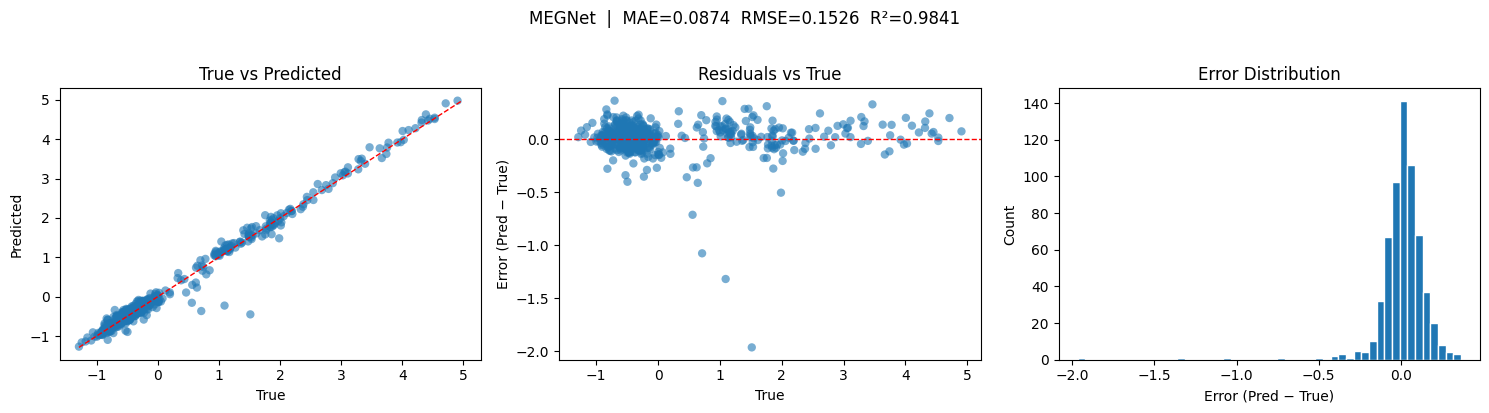

Plot saved to megnet_results.png


In [ ]:
# ── 8. Plot ──────────────────────────────────────────────────
errors = y_pred - y_true
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Parity plot
axes[0].scatter(y_true, y_pred, alpha=0.6, edgecolors="none")
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("True")
axes[0].set_ylabel("Predicted")
axes[0].set_title("True vs Predicted")

# Residual plot
axes[1].scatter(y_true, errors, alpha=0.6, edgecolors="none")
axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
axes[1].set_xlabel("True")
axes[1].set_ylabel("Error (Pred − True)")
axes[1].set_title("Residuals vs True")

# Error distribution
axes[2].hist(errors, bins=50, edgecolor="white")
axes[2].set_xlabel("Error (Pred − True)")
axes[2].set_ylabel("Count")
axes[2].set_title("Error Distribution")

plt.suptitle(f"MEGNet  |  MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}", y=1.02)
plt.tight_layout()
plt.savefig("megnet_results.png", dpi=300, bbox_inches="tight")
plt.show()
print("Plot saved to megnet_results.png")